In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
import spiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from kepler_utils import *
import batman_utils

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   #stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!
A = .1                                      # ASSUMPTION (!): Band-integrated albedo of rocky surface stays approx. const at A=.1 (reflected part negligible)

In [3]:
# Define Exoplanet Object
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

In [4]:
# Wavelength ranges of various instruments in um. These are only effective ranges, used for approximate tophat filters.
effective_lambda_ranges = {
    "MIRI/F1280W": [11.6, 14.0], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [13.5, 16.6], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), Long wavelengths for cold nightside
    "MIRI/F1800W": [16.5, 19.5], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "MIRI/LRS": [5.0, 10.5], # Suggested by Sebastian, LRS runs to ~12 µm but red end trimmed (throughput drops)
    "Spitzer/IRAC2": [4.0, 5.0] # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
}
for n, r in effective_lambda_ranges.items(): effective_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

# Wavelength ranges of various instruments in um. These are the exact filter ranges to be used with the filter throughput data.
filter_lambda_ranges = {
    "MIRI/F1280W": [11.0654, 14.5816], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [12.7875, 17.4925], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), good for cold nightside
    "MIRI/F1800W": [15.5725, 20.8505], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "Spitzer/IRAC2": [3.6955, 5.1008], # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
    "MIRI/LRS": [4.8900, 10.6100] # MIRI/LRS 5.0-10.5 um. Filter_paths for 5.0-12.0 um and 5.0-14.0 um are also available.
}
for n, r in filter_lambda_ranges.items(): filter_lambda_ranges[n]=1e-6*np.array(r) # convert to meters

FILTER_DIR = os.path.join(os.path.dirname(os.path.abspath('')), 'Filters', 'Spiderman')
filter_paths = {
    "MIRI/F1280W": os.path.join(FILTER_DIR, "JWST_MIRI.F1280W.spiderman.dat"),
    "MIRI/F1500W": os.path.join(FILTER_DIR, "JWST_MIRI.F1500W.spiderman.dat"),
    "MIRI/F1800W": os.path.join(FILTER_DIR, "JWST_MIRI.F1800W.spiderman.dat"),
    "Spitzer/IRAC2": os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat"),
    "MIRI/LRS": os.path.join(FILTER_DIR, "MIRI_LRS.5.0-10.5um.spiderman.dat")
}

In [5]:
# Filter to be used
lrs_path = filter_paths["MIRI/LRS"]
lrs_range = filter_lambda_ranges["MIRI/LRS"]

## Detectability and parameter bias analysis (MIRI/LRS 5.0-10.5 um)

For K2-141b, MIRI/LRS 5.0-10.5 um has a detection error of 323ppm per minute. 

This entire analysis focuses on the thermal lightcurve and ignores the reflected part. This assumes that A=0.1 stays fixed in the NIR wavelength band while A_B changes.

In [6]:
minutes_binning = 15 # bin width [minutes]
sigma_1min      = 323. # detection error [ppm per minute], MIRI/LRS 5.0-10.5 um
n_orbits        = 10 # number of orbits observed (3 orbits has been done)

sigma_bin = sigma_1min / np.sqrt(minutes_binning * n_orbits) # [ppm]
print(f"period = {period*24*60:.1f} min -> {int(period*24*60/minutes_binning)} bins of {minutes_binning} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

period = 403.6 min -> 26 bins of 15 min
1-sigma per bin = 26.4 ppm


### 1. Pure Detectability

In [7]:
def bin_curve(t, y, minutes_binning):
    # Average y in fixed-width time bins. t in days, minutes_binning in minutes.
    dt = minutes_binning /60/24
    edges = np.arange(t[0], t[-1] + dt, dt) # bin edges
    idx = np.digitize(t, edges) - 1
    ok = (idx >= 0) & (idx < len(edges) - 1)
    nb = len(edges) - 1
    cnt = np.bincount(idx[ok], minlength=nb)
    tot = np.bincount(idx[ok], weights=y[ok], minlength=nb)
    m = cnt > 0
    t_bin = 0.5 * (edges[:-1] + edges[1:])
    return t_bin[m], tot[m] / cnt[m]

In [8]:
#Comparing to Louden instead of thermal_PhaseCurve(insolation_model="naive") for faster runtimes
t_k, pc_k, fp_k, _ = thermal_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A_B=A_B, N_LAYERS=120, insolation_model="kopal")
t_n, pc_n, fp_n, _ = Louden_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A_B=A_B, N_LAYERS=120)
_, lc_k, _, _ = thermal_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A_B=A_B, N_LAYERS=120, insolation_model="kopal", include_transit=False, include_occultation=False)
_, lc_n, _, _ = Louden_PhaseCurve(K2_141b, lrs_range, u=u, filter_path=lrs_path, A_B=A_B, N_LAYERS=120, include_transit=False, include_occultation=False)

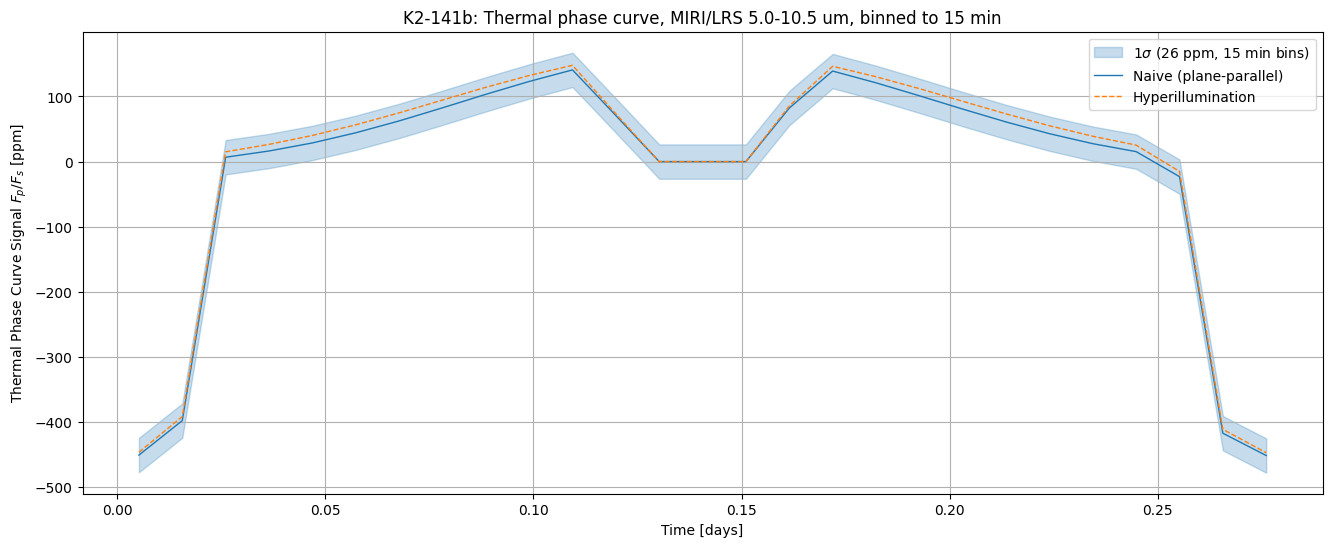

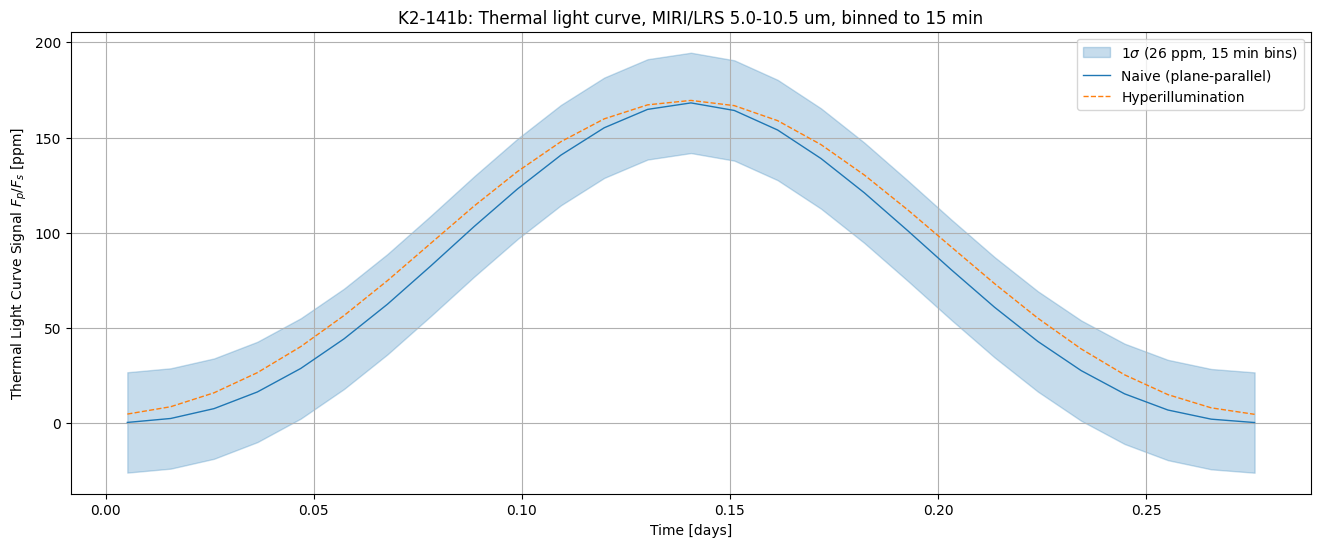

In [9]:
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_n, yb_n - sigma_bin, yb_n + sigma_bin, color="C0", alpha=0.25, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Phase Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: Thermal phase curve, MIRI/LRS 5.0-10.5 um, binned to {minutes_binning} min")
plt.legend(); plt.grid()
plt.show()

tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_n, yb_n - sigma_bin, yb_n + sigma_bin, color="C0", alpha=0.25, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: Thermal light curve, MIRI/LRS 5.0-10.5 um, binned to {minutes_binning} min")
plt.legend(); plt.grid()
plt.show()

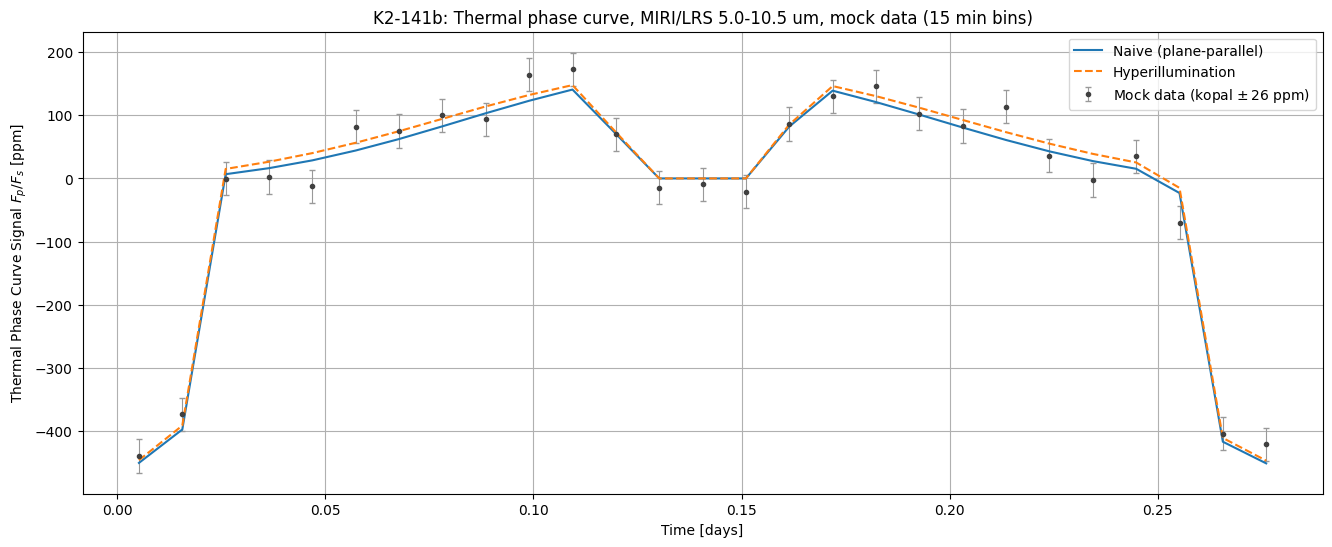

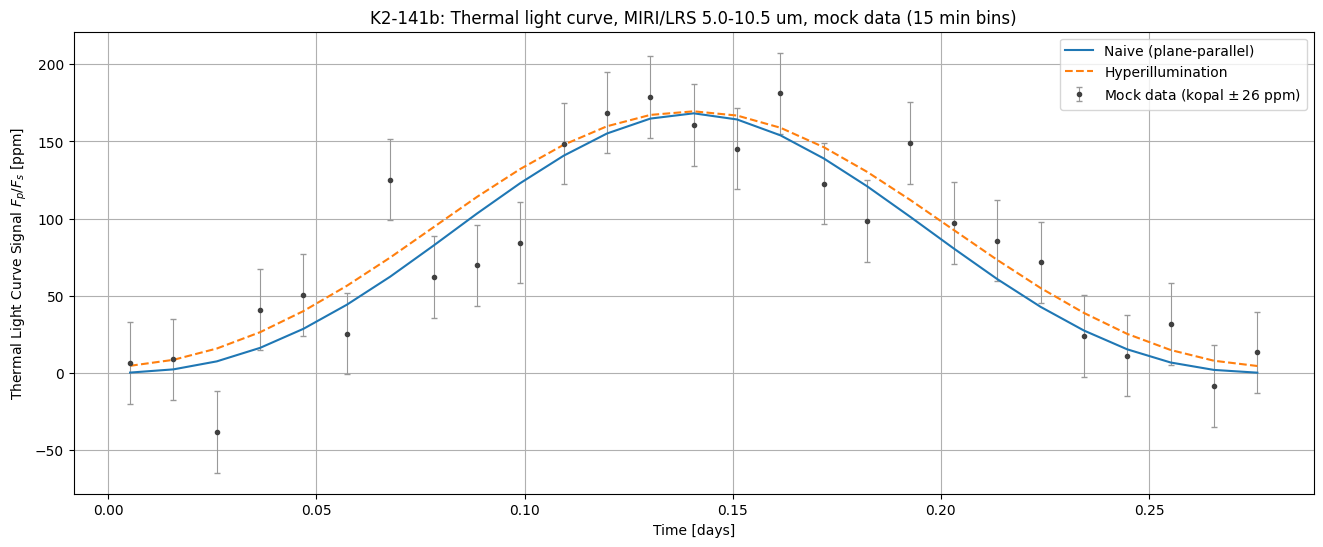

In [10]:
# Mock observation: at each binned time draw a data point ~ N(mean = naive model, std = sigma_bin),
# shown with sigma_bin error bars (instead of the 1-sigma envelope above) -- for phase curve and light curve.
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)        # mock data ~ N(hyperillumination, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_n, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (kopal $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Phase Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: Thermal phase curve, MIRI/LRS 5.0-10.5 um, mock data ({minutes_binning} min bins)")
plt.legend(); plt.grid()
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_n, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (kopal $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal $F_p/F_s$ [ppm]")
plt.title(f"K2-141b: Thermal light curve, MIRI/LRS 5.0-10.5 um, mock data ({minutes_binning} min bins)")
plt.legend(); plt.grid()
plt.show()

### 2. Bias in recovered Bond albedo when hyperillumination is neglected

In [11]:
l1, l2 = lrs_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=lrs_path)

A_B_true = A_B  # 3/2 * Ag(Zieba2022) = 0.42

# Fast, stripped-down version of thermal_PhaseCurve() purpose-built for the fitting loop
def model_lc(insolation_model, A_B_, a_rs=a, T_s=T_eff, rp_=rp, n_t=100, n_layers=120,
             n_lo=300, n_la=150):
    """Occultation-inclusive light curve [ppm] on a fixed time grid."""
    t_ = np.linspace(0., period, int(n_t))
    lo, la, Tg = custom_temperature_grid(replace(K2_141b, R=a_rs, T2_eff=T_s, r1=rp_), n_lo=n_lo, n_la=n_la,
                                         insolation_model=insolation_model, A_B=A_B_)
    LO, LA = np.meshgrid(lo, la, indexing="ij")
    p = sp.ModelParams(brightness_model="direct_T", stellar_model="blackbody")
    p.n_layers = n_layers
    p.t0, p.per = 0., period
    p.a_abs = a_rs * rs * 6.957e8 / 1.495978707e11
    p.inc, p.ecc, p.w = incl, ecc, w
    p.rp, p.a = rp_, a_rs
    p.p_u1 = p.p_u2 = 0.
    p.T_s, p.l1, p.l2 = T_s, l1, l2
    p.grid = sp.format_grid(LO, LA, np.maximum(Tg, 100.).T)
    p.filter, p.eclipse = lrs_path, True
    return t_, (p.lightcurve(t_, stellar_grid=stellar_grid) - 1) * 1e6

no stellar models provided, using blackbody approximation


In [12]:
def fit_naive(truth, free_offset=True, bounds=(0.15, 0.55), **kw):
    """Best-fit naive A_B against hyperillumination-generated data."""
    def cost(A_):
        r = truth - model_lc("naive", A_, **kw)[1]
        if free_offset: r = r - r.mean()      # real TSO fits have a free baseline
        return np.sum((r / sigma_bin) ** 2)
    res = minimize_scalar(cost, bounds=bounds, method="bounded",
                          options={"xatol": 1e-4})
    A_fit, chi2_fit = res.x, res.fun # chi2_fit=cost(A_fit) is the weighted sum of squared residuals
    return A_fit, chi2_fit

_, truth = model_lc("kopal", A_B_true)

for free_offset in (False, True):
    A_fit, chi2 = fit_naive(truth, free_offset=free_offset)
    r = truth - model_lc("naive", A_fit)[1]
    if free_offset: r = r - r.mean()
    print(f"free offset={str(free_offset):5s}  A_B: {A_B_true:.3f} -> {A_fit:.4f}  "
          f"bias={A_fit-A_B_true:+.4f} ({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  "
          f"chi2={chi2:.4f}  resid_rms={np.sqrt(np.mean(r**2)):.2f} ppm  "
          f"significance={np.sqrt(chi2):.3f} sigma/observation")

free offset=False  A_B: 0.420 -> 0.2729  bias=-0.1471 (-35.0%)  chi2=4.9178  resid_rms=5.85 ppm  significance=2.218 sigma/observation
free offset=True   A_B: 0.420 -> 0.3742  bias=-0.0458 (-10.9%)  chi2=2.0435  resid_rms=3.77 ppm  significance=1.430 sigma/observation


In [13]:
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
# Convergence: the bias is a small model difference and inherits the terminator-kink error.
# The 5 resolution settings are independent -> run them in parallel (processes; joblib).
settings = [(30, 24, 120), (50, 40, 200), (80, 60, 200), (120, 100, 300), (120, 150, 300)]

def conv_bias(NL, NT, NLO):
    kw = dict(n_layers=NL, n_t=NT, n_lo=NLO, n_la=NLO // 2)
    _, tr = model_lc("kopal", A_B_true, **kw)
    A_fit, _ = fit_naive(tr, **kw)
    return A_fit - A_B_true

biases = Parallel(n_jobs=-1, backend="loky")(delayed(conv_bias)(NL, NT, NLO) for NL, NT, NLO in settings)
for (NL, NT, NLO), b in zip(settings, biases):
    print(f"n_layers={NL:4d} n_t={NT:4d} grid={NLO}x{NLO//2}  bias={b:+.4f}")
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


n_layers=  30 n_t=  24 grid=120x60  bias=-0.0677
n_layers=  50 n_t=  40 grid=200x100  bias=-0.0542
n_layers=  80 n_t=  60 grid=200x100  bias=-0.0430
n_layers= 120 n_t= 100 grid=300x150  bias=-0.0458
n_layers= 120 n_t= 150 grid=300x150  bias=-0.0490
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


#### free_offset=True

/tmp/ipykernel_45745/1787220897.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  for a_ in ax: a_.grid(alpha=.3); a_.legend()


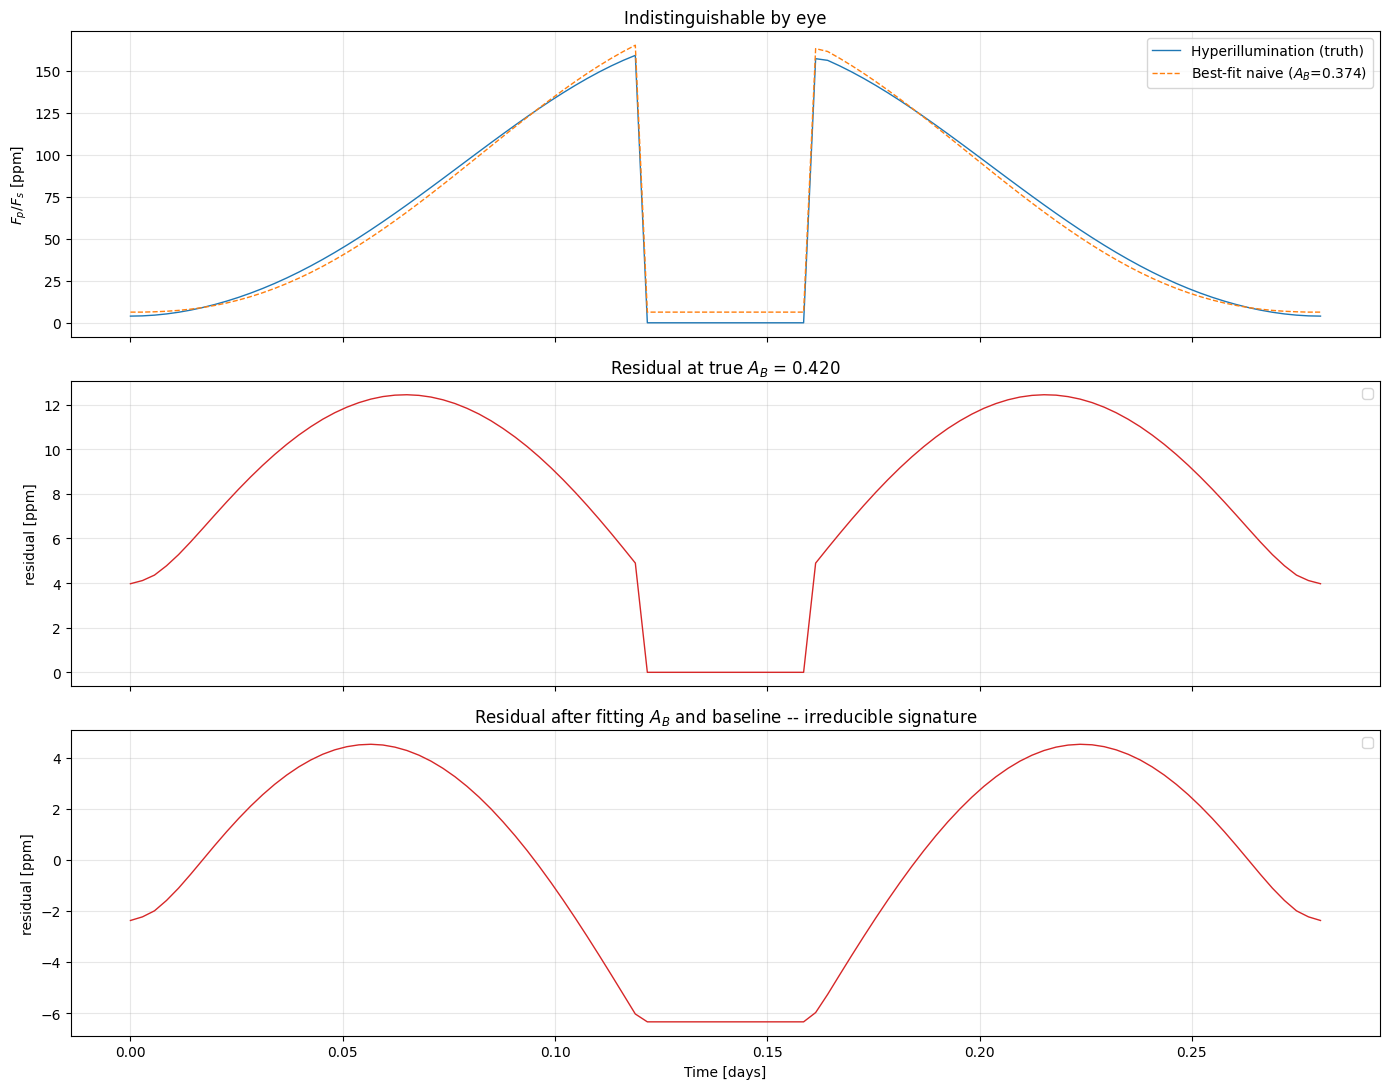

In [14]:
# before vs after absorbing the bias into A_B
t_, truth = model_lc("kopal", A_B_true)
A_fit, _  = fit_naive(truth)
naive_0   = model_lc("naive", A_B_true)[1]
naive_f   = model_lc("naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
ax[0].plot(t_, truth,   lw=1, label="Hyperillumination (truth)")
ax[0].plot(t_, naive_f, lw=1, ls="--", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_title("Indistinguishable by eye")
#ax[1].axhspan(-sigma_bin, sigma_bin, color="C0", alpha=.2, label=rf"$1\sigma$ = {sigma_bin:.0f} ppm")
ax[1].plot(t_, truth - naive_0, lw=1, color="C3")
ax[1].set_ylabel("residual [ppm]"); ax[1].set_title(rf"Residual at true $A_B$ = {A_B_true:.3f}")
#[2].axhspan(ymin, ymax, color="C0", alpha=.2)
ax[2].plot(t_, truth - naive_f, lw=1, color="C3")
ax[2].set_ylabel("residual [ppm]"); ax[2].set_xlabel("Time [days]")
ax[2].set_title(r"Residual after fitting $A_B$ and baseline -- irreducible signature")
#ax[2].set_ylim(ax[1].get_ylim())
for a_ in ax: a_.grid(alpha=.3); a_.legend()
fig.tight_layout()

#### free_offset=False

/tmp/ipykernel_45745/996602699.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  for a_ in ax: a_.grid(alpha=.3); a_.legend()


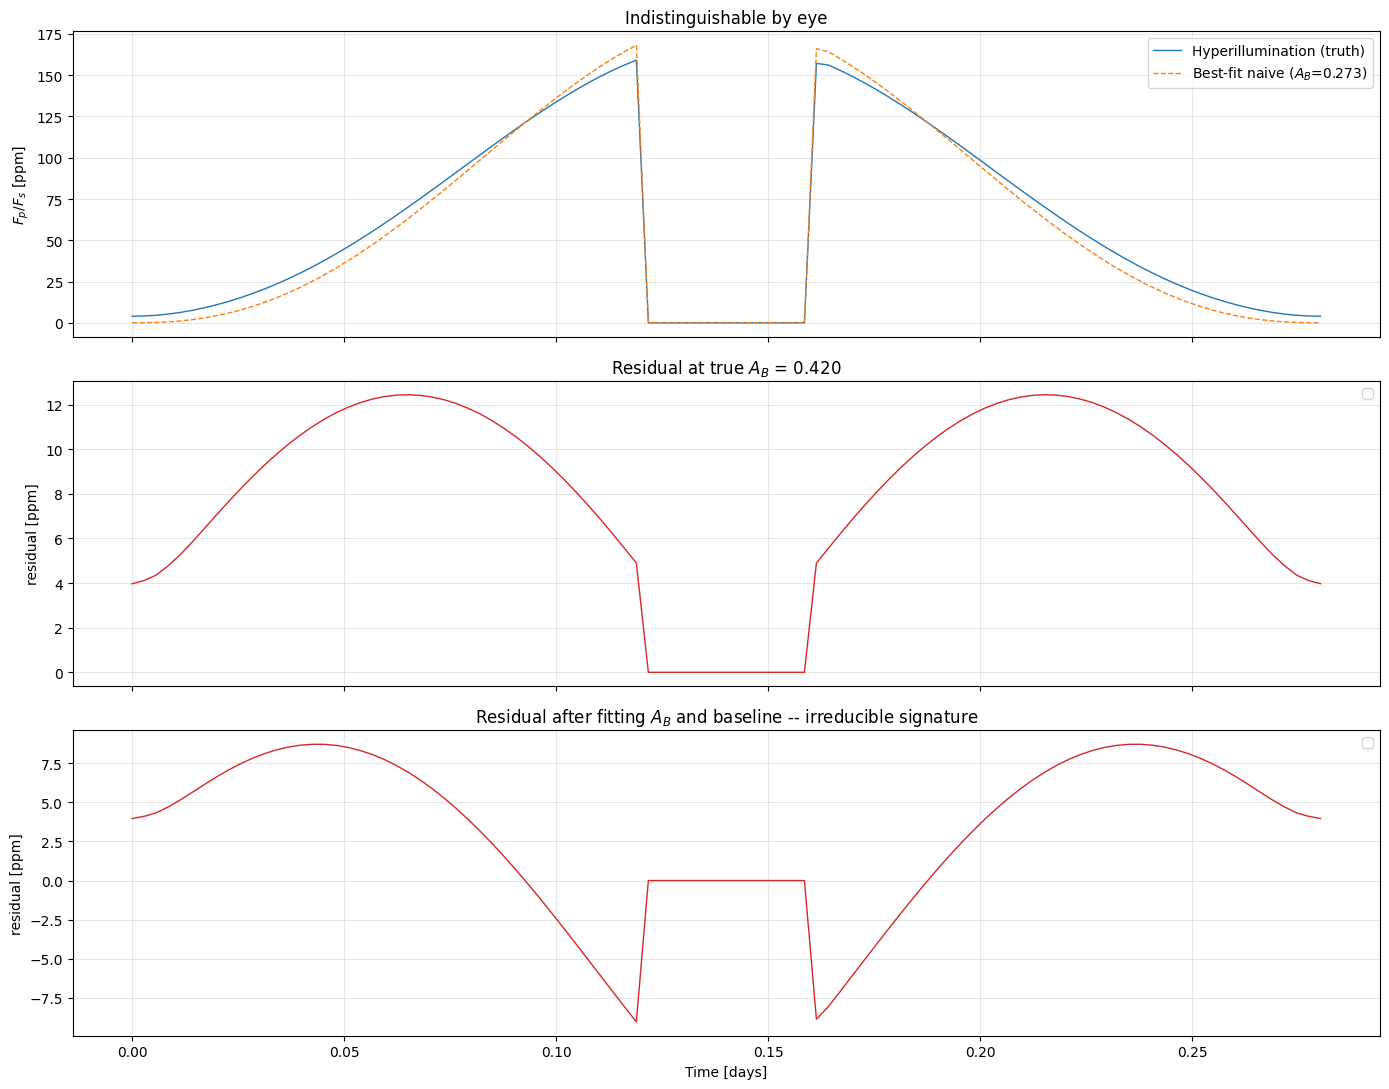

In [15]:
# before vs after absorbing the bias into A_B
t_, truth = model_lc("kopal", A_B_true)
A_fit, _  = fit_naive(truth, free_offset=False)
naive_0   = model_lc("naive", A_B_true)[1]
naive_f   = model_lc("naive", A_fit)[1]

fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
ax[0].plot(t_, truth,   lw=1, label="Hyperillumination (truth)")
ax[0].plot(t_, naive_f, lw=1, ls="--", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_title("Indistinguishable by eye")
#ax[1].axhspan(-sigma_bin, sigma_bin, color="C0", alpha=.2, label=rf"$1\sigma$ = {sigma_bin:.0f} ppm")
ax[1].plot(t_, truth - naive_0, lw=1, color="C3")
ax[1].set_ylabel("residual [ppm]"); ax[1].set_title(rf"Residual at true $A_B$ = {A_B_true:.3f}")
#[2].axhspan(ymin, ymax, color="C0", alpha=.2)
ax[2].plot(t_, truth - naive_f, lw=1, color="C3")
ax[2].set_ylabel("residual [ppm]"); ax[2].set_xlabel("Time [days]")
ax[2].set_title(r"Residual after fitting $A_B$ and baseline -- irreducible signature")
#ax[2].set_ylim(ax[1].get_ylim())
for a_ in ax: a_.grid(alpha=.3); a_.legend()
fig.tight_layout()

### 3. In which regimes does hyperillumination matter? Bias map over (a/Rs, T_eff)

#### free_offset=True

In [17]:
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma and of the target's brightness. The (a/Rs, T_eff) cells are independent -> run them in parallel (processes; joblib).
a_rs_grid  = np.linspace(1.5, 4.0, 20)
T_eff_grid = np.linspace(3000., 6000., 10)
kw = dict(n_t=60, n_layers=80, n_lo=200, n_la=100)     # ~3 s per cell

def bias_cell(ar, Ts, kw):
    _, tr = model_lc("kopal", A_B_true, a_rs=ar, T_s=Ts, **kw)
    A_fit, _ = fit_naive(tr, a_rs=ar, T_s=Ts, **kw)
    return A_fit - A_B_true

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(ar, Ts, kw) for Ts in T_eff_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(T_eff_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for 

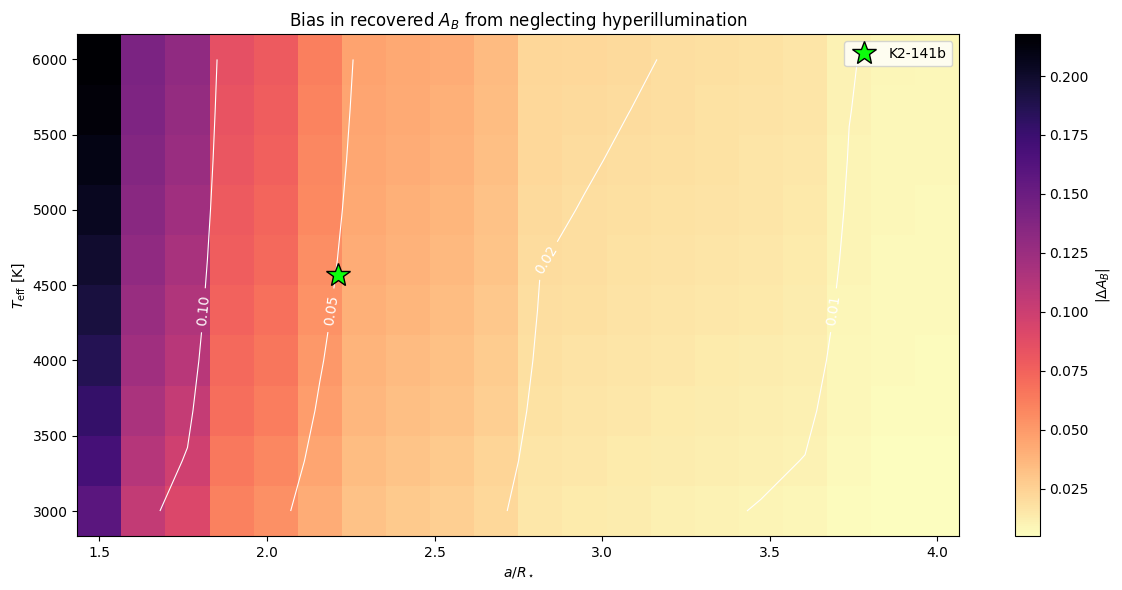

In [18]:
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(a_rs_grid, T_eff_grid, np.abs(bias_map), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, T_eff_grid, np.abs(bias_map), levels=[0.01, 0.02, 0.05, 0.10],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
ax.plot(a/1, T_eff, "*", color="#0cff0c", ms=18, mec="k", label="K2-141b")
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$T_{\rm eff}$ [K]")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(); fig.tight_layout()

#### free_offset=False

In [19]:
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma and of the target's brightness. The (a/Rs, T_eff) cells are independent -> run them in parallel (processes; joblib).
a_rs_grid  = np.linspace(1.5, 4.0, 20)
T_eff_grid = np.linspace(3000., 6000., 10)
kw = dict(n_t=60, n_layers=80, n_lo=200, n_la=100)     # ~3 s per cell

def bias_cell(ar, Ts, kw):
    _, tr = model_lc("kopal", A_B_true, a_rs=ar, T_s=Ts, **kw)
    A_fit, _ = fit_naive(tr, free_offset=False, a_rs=ar, T_s=Ts, **kw)
    return A_fit - A_B_true

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(ar, Ts, kw) for Ts in T_eff_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(T_eff_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for 

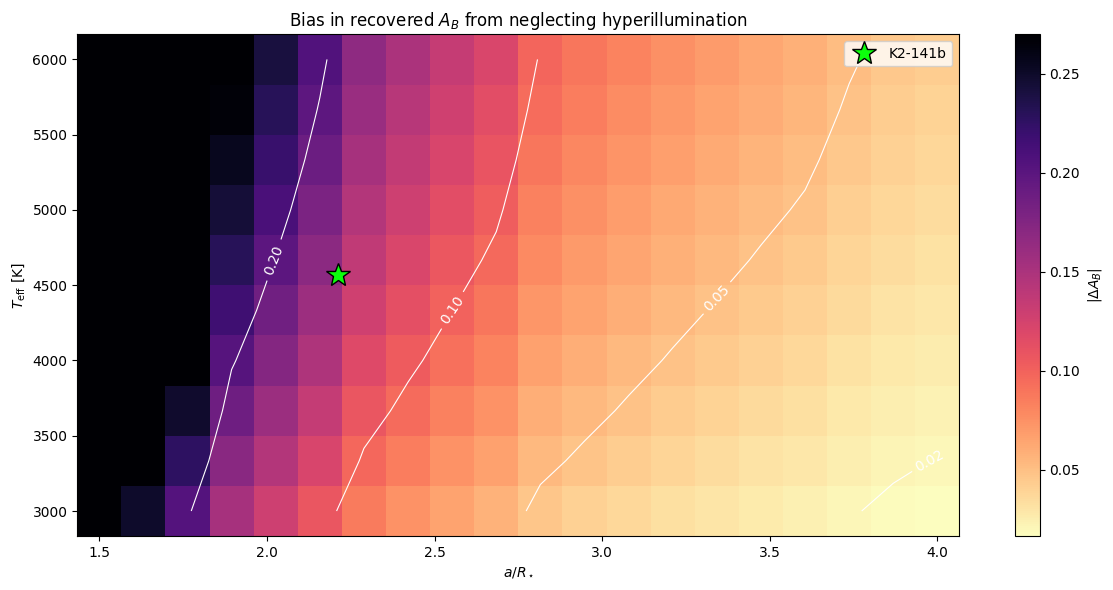

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(a_rs_grid, T_eff_grid, np.abs(bias_map), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, T_eff_grid, np.abs(bias_map), levels=[0.01, 0.02, 0.05, 0.10, 0.2],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
ax.plot(a/1, T_eff, "*", color="#0cff0c", ms=18, mec="k", label="K2-141b")
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$T_{\rm eff}$ [K]")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(); fig.tight_layout()

### 4. In which regimes does hyperillumination matter? Bias map over (a/Rs, Rp/Rs)

#### free_offset=True

In [21]:
a_rs_grid  = np.linspace(1.5, 4.0, 20)
rp_rs_grid = np.linspace(0.01, 0.1, 10)
kw = dict(n_t=60, n_layers=80, n_lo=200, n_la=100)     # ~3 s per cell

def bias_cell(ar, rpp, kw):
    _, tr = model_lc("kopal", A_B_true, a_rs=ar, rp_=rpp, **kw)
    A_fit, _ = fit_naive(tr, a_rs=ar, rp_=rpp, **kw)
    return A_fit - A_B_true

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(ar, rpp, kw) for rpp in rp_rs_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(rp_rs_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for 

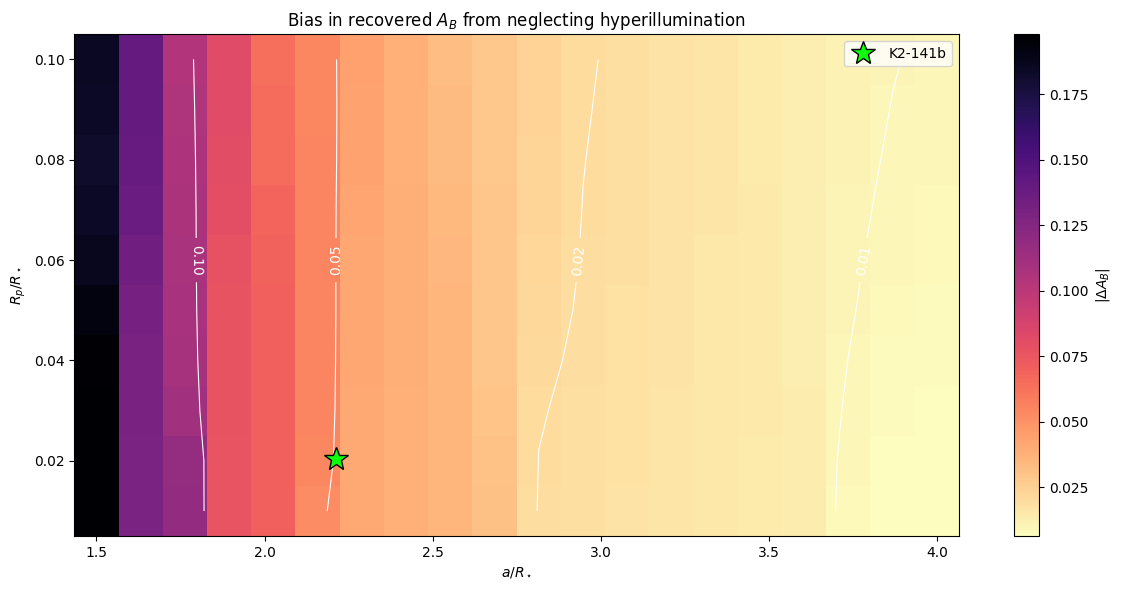

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(a_rs_grid, rp_rs_grid, np.abs(bias_map), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, rp_rs_grid, np.abs(bias_map), levels=[0.01, 0.02, 0.05, 0.10],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
ax.plot(a/1, rp, "*", color="#0cff0c", ms=18, mec="k", label="K2-141b")
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$R_p/R_\star$")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(); fig.tight_layout()

#### free_offset=False

In [23]:
a_rs_grid  = np.linspace(1.5, 4.0, 20)
rp_rs_grid = np.linspace(0.01, 0.1, 10)
kw = dict(n_t=60, n_layers=80, n_lo=200, n_la=100)     # ~3 s per cell

def bias_cell(ar, rpp, kw):
    _, tr = model_lc("kopal", A_B_true, a_rs=ar, rp_=rpp, **kw)
    A_fit, _ = fit_naive(tr, free_offset=False, a_rs=ar, rp_=rpp, **kw)
    return A_fit - A_B_true

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(ar, rpp, kw) for rpp in rp_rs_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(rp_rs_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected
looking for 

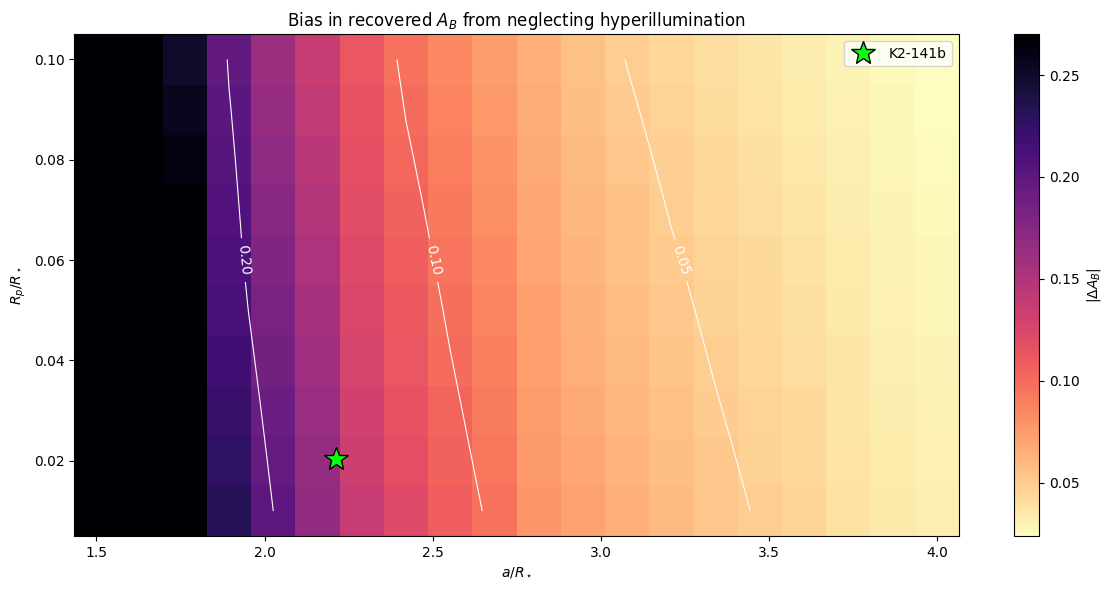

In [24]:
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.pcolormesh(a_rs_grid, rp_rs_grid, np.abs(bias_map), cmap="magma_r", shading="auto")
cs = ax.contour(a_rs_grid, rp_rs_grid, np.abs(bias_map), levels=[0.01, 0.02, 0.05, 0.10, 0.2],
                colors="w", linewidths=.8)
ax.clabel(cs, fmt="%.2f")
ax.plot(a/1, rp, "*", color="#0cff0c", ms=18, mec="k", label="K2-141b")
ax.set_xlabel(r"$a/R_\star$"); ax.set_ylabel(r"$R_p/R_\star$")
ax.set_title(r"Bias in recovered $A_B$ from neglecting hyperillumination")
fig.colorbar(im, ax=ax, label=r"$|\Delta A_B|$")
ax.legend(); fig.tight_layout()